In [11]:
import pandas as pd
import numpy as np
from ucimlrepo import fetch_ucirepo 
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import classification_report, confusion_matrix, fbeta_score, roc_auc_score, precision_recall_curve, auc

In [47]:
# fetch dataset 
breast_cancer_wisconsin_diagnostic = fetch_ucirepo(id=17) # Data set: https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic
  
# data (as pandas dataframes) 
X = breast_cancer_wisconsin_diagnostic.data.features 
y = breast_cancer_wisconsin_diagnostic.data.targets

y["Diagnosis"] = y["Diagnosis"].map({"M": 1, "B": 0})
# metadata 
print(breast_cancer_wisconsin_diagnostic.metadata) 
  
# variable information 
print(breast_cancer_wisconsin_diagnostic.variables) 

{'uci_id': 17, 'name': 'Breast Cancer Wisconsin (Diagnostic)', 'repository_url': 'https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic', 'data_url': 'https://archive.ics.uci.edu/static/public/17/data.csv', 'abstract': 'Diagnostic Wisconsin Breast Cancer Database.', 'area': 'Health and Medicine', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 569, 'num_features': 30, 'feature_types': ['Real'], 'demographics': [], 'target_col': ['Diagnosis'], 'index_col': ['ID'], 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 1993, 'last_updated': 'Fri Nov 03 2023', 'dataset_doi': '10.24432/C5DW2B', 'creators': ['William Wolberg', 'Olvi Mangasarian', 'Nick Street', 'W. Street'], 'intro_paper': {'ID': 230, 'type': 'NATIVE', 'title': 'Nuclear feature extraction for breast tumor diagnosis', 'authors': 'W. Street, W. Wolberg, O. Mangasarian', 'venue': 'Electronic imaging', 'year': 1993, 'journal': None, 'DOI': '1

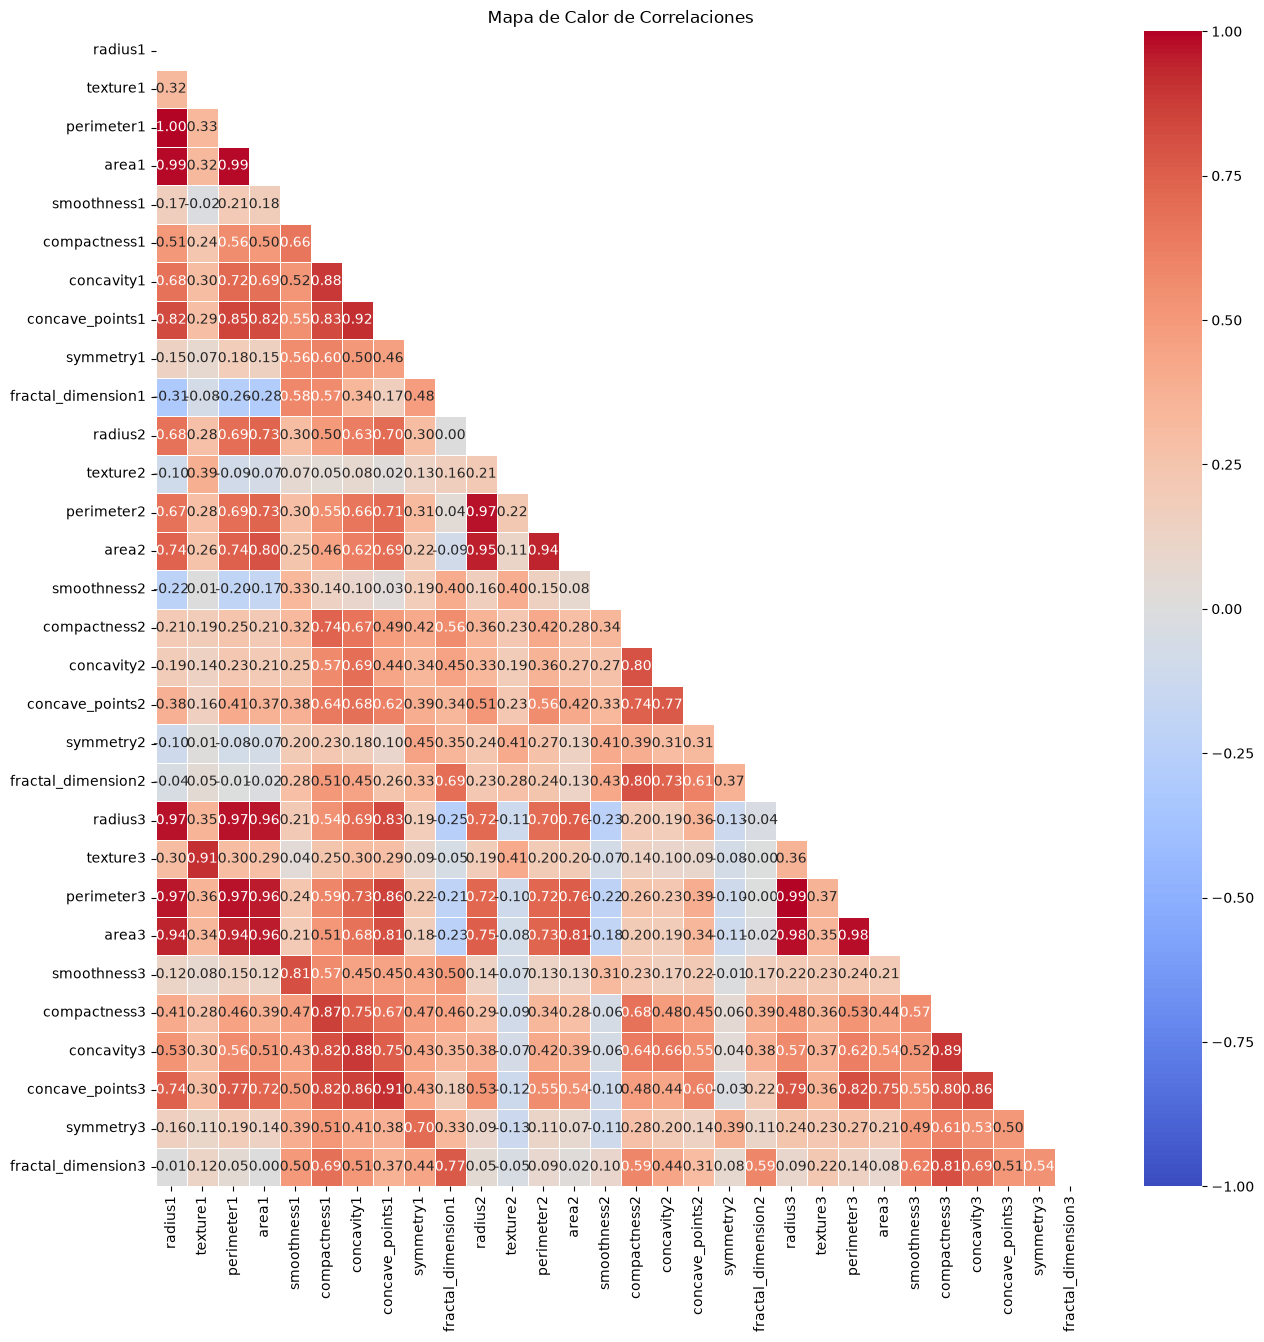

In [10]:
matriz_corr = X.corr(method="pearson")

# 2. Representación mediante Heatmap
plt.figure(figsize=(15, 15))
# MÁSCARA para ocultar la mitad superior simétrica redundante
mascara = np.triu(np.ones_like(matriz_corr, dtype=bool))

sns.heatmap(
    matriz_corr, 
    mask=mascara,
    annot=True,          # Muestra el valor numérico
    fmt=".2f",           # Formato de dos decimales
    cmap="coolwarm",     # Paleta divergente (rojo=positivo, azul=negativo)
    vmin=-1, vmax=1,     # Escala fija de correlación
    linewidths=0.5
)
plt.title("Mapa de Calor de Correlaciones")
plt.show()

C:\Users\jose.delaasuncion\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


0.9766081871345029


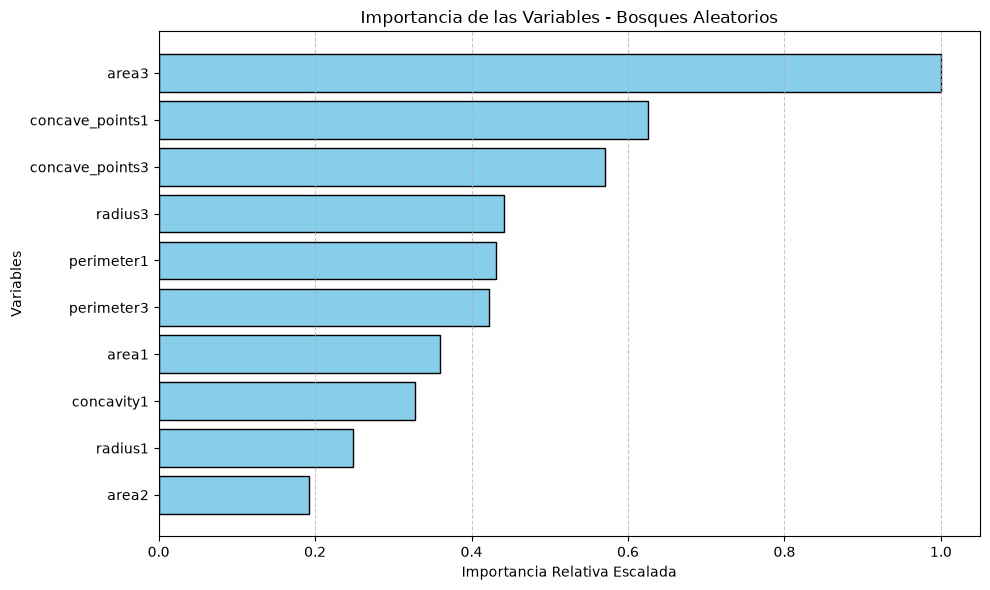

In [51]:
# Prep dataset entrenamiento y test

X_train,X_test, y_train, y_test = train_test_split(
    X,y,
    test_size=0.3,
    stratify=y,
    random_state=42
)

modelo_rf = RandomForestClassifier(
    n_estimators=100,         # Número de árboles en el bosque
    max_depth=10,
    min_samples_split= 5,
    min_samples_leaf=4,
    random_state=42,
    n_jobs=-1
)

modelo_rf.fit(X_train, y_train)

score_rf = modelo_rf.score(X_test, y_test)
print(score_rf)

# Importancia relativa de las variables
importancias_rf = modelo_rf.feature_importances_
importances_rf = importancias_rf / np.max(importancias_rf)
indices = np.argsort(importances_rf)[::-1]

# Selección de las N variables más importantes
top_n = 10
indices_top = indices[:top_n]
indices_predictores = X.columns.values

# Graficamos el resultado
plt.figure(figsize=(10,6))
plt.barh(range(top_n), importances_rf[indices_top][::-1], color='skyblue', edgecolor='black')
plt.yticks(range(top_n), indices_predictores[indices_top][::-1])

plt.xlabel('Importancia Relativa Escalada')
plt.ylabel('Variables')
plt.title('Importancia de las Variables - Bosques Aleatorios')
plt.grid(axis='x', linestyle='--', alpha=0.7) # Añade líneas guía de fondo
plt.tight_layout()
plt.show()

In [52]:
# Definición del Pipeline
pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", RandomForestClassifier(random_state=42))
])

# Espacio de hiperparámetros (sintaxis: nombrepaso__nombreparametro)
param_grid = {
    "classifier__n_estimators": [50, 100, 150 , 200, 250],
    "classifier__max_depth": [4, 5, 6,7, 8, 9,10, None],
    "classifier__min_samples_split": [2,4, 5,6,8, 10],
    "classifier__min_samples_leaf": [2,3, 4,5]
}

param_grid2 = {
    "classifier__n_estimators": [50, 200],
    "classifier__max_depth": [6,7, 8],
    "classifier__min_samples_split": [2,3],
    "classifier__min_samples_leaf": [2,3]
}

# Validación Cruzada Estratificada
cv_estratificado = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 4. Búsqueda exhaustiva optimizando por la métrica de interés (ej. recall, f2, roc_auc)
grid_search = GridSearchCV(
    estimator=pipe,
    param_grid=param_grid2,
    scoring="roc_auc",       # O 'recall', 'f1', 'f2' según el dominio
    cv=cv_estratificado,
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print(f"Mejor combinación: {grid_search.best_params_}")
print(f"Mejor puntuación de CV: {grid_search.best_score_:.4f}")

Mejor combinación: {'classifier__max_depth': 7, 'classifier__min_samples_leaf': 3, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 200}
Mejor puntuación de CV: 0.9862


C:\Users\jose.delaasuncion\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


In [59]:
mejor_modelo = grid_search.best_estimator_
y_probs = mejor_modelo.predict_proba(X_test)[:, 1]

# Ajustar manualmente el umbral de decisión
umbral_personalizado = 0.16  # Al bajar el umbral, se incrementa el Recall

# Generar nuevas predicciones basadas en el umbral ajustado
y_pred_ajustado = (y_probs >= umbral_personalizado).astype(int)

# Imprimir la matriz de confusión
print(confusion_matrix(y_test, y_pred_ajustado))

# ROC-AUC
score_roc = roc_auc_score(y_test, y_probs)

# PR-AUC
precisiones, recalls, umbrales = precision_recall_curve(y_test, y_probs)
score_pr_auc = auc(recalls, precisiones)

print(f"ROC-AUC: {score_roc:.4f} | PR-AUC: {score_pr_auc:.4f}")


# ROC-AUC
score_roc_ad = roc_auc_score(y_test, y_pred_ajustado)

# PR-AUC
precisiones, recalls, umbrales = precision_recall_curve(y_test, y_pred_ajustado)
score_pr_auc = auc(recalls, precisiones)

print(f"ROC-AUC: {score_roc:.4f} | PR-AUC: {score_pr_auc:.4f}")

[[96 11]
 [ 0 64]]
ROC-AUC: 0.9963 | PR-AUC: 0.9945
ROC-AUC: 0.9963 | PR-AUC: 0.9267
